In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as skimage_psnr
from skimage.metrics import structural_similarity as skimage_ssim
import os

In [3]:
model_name = 'mnist'
exp_root = 'exps/mayoct/results/inverse/mayoct/tomo'
if model_name == 'mnist':
    num_angles = ['11', '22', '33']
psnr_stack = []
min_psnr_stack = []
max_psnr_stack = []
ssim_stack = []
min_ssim_stack = []
max_ssim_stack = []

mean_mean = []
mean_std = []

stack_interest = []
stack_psnr_mean = []
stack_std_mean = []
stack_std = []

std_maxes = []

for angle in num_angles:
    dir_name = os.listdir(exp_root)
    dir_name = sorted(dir_name)
    filtered_dir_name = []
    if model_name == 'mnist':
        filter_name = f'idood_valid_num_angles={angle}_det_shape=22_'
        for dir  in dir_name:
            if filter_name in dir and 'cifar' not in dir:
                filtered_dir_name.append(dir)

    total_psnrs = []
    total_ssims = []
    xhat_lists = []
    total_psnrs_100 = []
    total_ssims_100 = []

    for exp_name in filtered_dir_name:
        psnrs_100 = []
        ssims_100 = []
        # print(exp_name)
        
        num_imgs = 100
        fbp_list = []
        gt_list = []
        xhat_list = []
        y_list = []
        for i in range(num_imgs):
            y_list.append(np.load(f'{exp_root}/{exp_name}/lpn/y/{i}.npy'))
            fbp_list.append(np.load(f'{exp_root}/{exp_name}/lpn/fbp/{i}.npy'))
            gt_list.append(np.load(f'{exp_root}/{exp_name}/lpn/x/{i}.npy'))
            xhat_list.append(np.load(f'{exp_root}/{exp_name}/lpn/xhat/{i}.npy'))
        xhat_list = np.array(xhat_list)
        gt_list = np.array(gt_list)
        root_dir = 'datasets'
        if model_name == 'mnist':
            label_list = np.load('exps/mayoct/models_mnist/prior_idood_noAug_1_1234/cvx_cg/gaussian/all/labels.npy').astype(int)
            img_size = 28
            fbp_psnr = []
            model_psnr = []
            psnrs = np.zeros((3,10))
            ssims = np.zeros((3,10))
            new_order = np.argsort(label_list)
            label_list = label_list[new_order]
            xhat_list = xhat_list[new_order]
            gt_list = gt_list[new_order]
            for i in range(num_imgs):
                psnr_model = skimage_psnr(gt_list[i], xhat_list[i], data_range=1.0)
                ssim_model = skimage_ssim(gt_list[i], xhat_list[i], data_range=1.0)
                psnrs_100.append(psnr_model)
                ssims_100.append(ssim_model)
                psnr_fbp = skimage_psnr(gt_list[i], fbp_list[i], data_range=1.0)
                ssim_fbp = skimage_ssim(gt_list[i], fbp_list[i], data_range=1.0)
                psnrs[0,label_list[i]] += 1
                psnrs[1,label_list[i]] += psnr_model
                psnrs[2,label_list[i]] += psnr_fbp
                ssims[0,label_list[i]] += 1
                ssims[1,label_list[i]] += ssim_model
                ssims[2,label_list[i]] += ssim_fbp
            psnrs[1] = psnrs[1]/psnrs[0]
            psnrs[2] = psnrs[2]/psnrs[0]
            ssims[1] = ssims[1]/ssims[0]
            ssims[2] = ssims[2]/ssims[0]

        if model_name == 'mnist':
            x = np.linspace(0, 9, 10).astype(int)

        xhat_lists.append(xhat_list)
        total_psnrs.append(psnrs)
        total_ssims.append(ssims)
        total_psnrs_100.append(psnrs_100)
        total_ssims_100.append(ssims_100)
    total_psnrs_100 = np.array(total_psnrs_100)
    total_ssims_100 = np.array(total_ssims_100)

    total_psnrs_100_mean = np.mean(total_psnrs_100, axis = 0)
    total_ssims_100_mean = np.mean(total_ssims_100, axis = 0)
    total_psnrs_100_std = np.std(total_psnrs_100, axis = 0)
    total_ssims_100_std = np.std(total_ssims_100, axis = 0)
    mean_psnrs  = np.mean(total_psnrs, axis=0)
    max_psnrs  = np.max(total_psnrs, axis=0)
    min_psnrs  = np.min(total_psnrs, axis=0)
    mean_ssims  = np.mean(total_ssims, axis=0)
    max_ssims  = np.max(total_ssims, axis=0)
    min_ssims  = np.min(total_ssims, axis=0)

    psnr_stack.append(mean_psnrs)
    min_psnr_stack.append(min_psnrs)
    max_psnr_stack.append(max_psnrs)
    ssim_stack.append(mean_ssims)
    min_ssim_stack.append(min_ssims)
    max_ssim_stack.append(max_ssims)

    x_arrays_std = np.std(xhat_lists, axis = 0).reshape(10,10,img_size,img_size)
    std_maxes.append(np.std(xhat_lists, axis = 0).max())
    stack_std.append(x_arrays_std)
    x_arrays_mean = np.mean(xhat_lists, axis = 0)
    x_arrays_mean_label = np.mean(x_arrays_mean.reshape(10,10,img_size,img_size), axis = 1)
    x_arrays_std_label = np.mean(x_arrays_std, axis = 1) 
    temp = x_arrays_mean.reshape(10,10, img_size, img_size)
    gt_temp = gt_list.reshape(10,10, img_size, img_size)
    gt_all = gt_temp
    stack_interest.append(temp)
    stack_psnr_mean.append(total_psnrs_100_mean.reshape(10,10))
    stack_std_mean.append(total_psnrs_100_std.reshape(10,10))

    mean_std.append(x_arrays_std_label)
    mean_mean.append(x_arrays_mean_label)

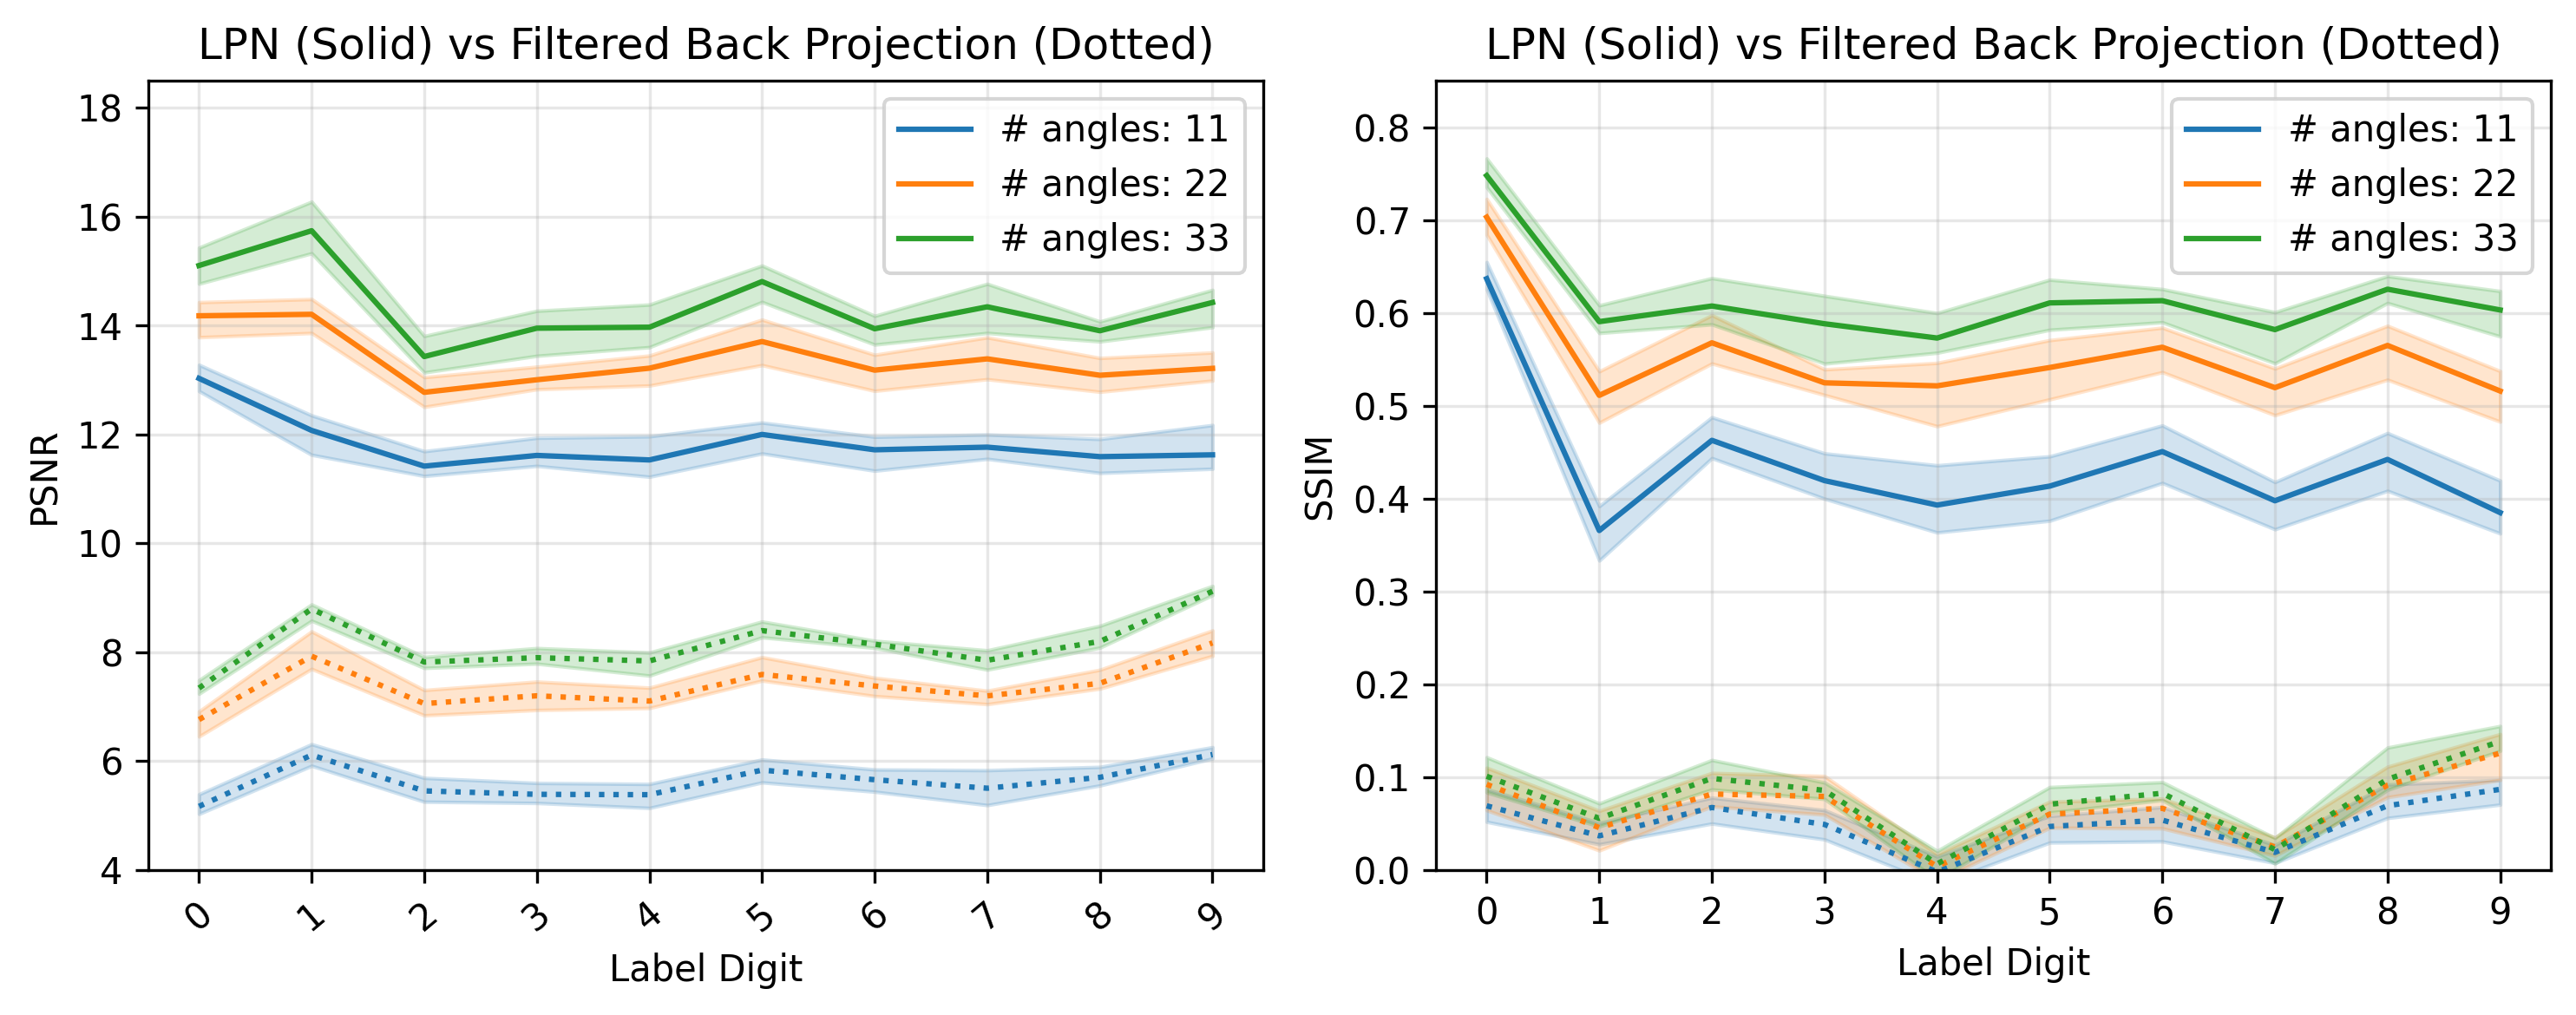

In [4]:
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
plt.figure(figsize = (10,4),dpi=300)
plt.subplot(1,2,1)
for model_method in range(1,3):
    for angle in range(len(num_angles)):
        if model_method == 1:
            label_name = f'# angles: {num_angles[angle]}'
            linestyle = '-'
        else:
            label_name = None
            linestyle = ':'
        plt.plot(x,psnr_stack[angle][model_method], label = label_name, ls = linestyle, c = colors[angle])
        plt.fill_between(x, max_psnr_stack[angle][model_method], min_psnr_stack[angle][model_method], alpha=0.2, color = colors[angle])
        plt.xlabel('Label Digit')
        plt.ylabel('PSNR')
plt.legend(loc = 'upper right')
plt.grid('on', alpha=0.3)
if model_name == 'mnist':
    plt.xticks(range(0, 10, 1), rotation = 40)
    plt.ylim([4,18.5])
plt.title('LPN (Solid) vs Filtered Back Projection (Dotted)')
plt.subplot(1,2,2)
for model_method in range(1,3):
    for angle in range(len(num_angles)):
        if model_method == 1:
            label_name = f'# angles: {num_angles[angle]}'
            linestyle = '-'
        else:
            label_name = None
            linestyle = ':'
        plt.plot(x,ssim_stack[angle][model_method], label = label_name, ls = linestyle, c = colors[angle])
        plt.fill_between(x, max_ssim_stack[angle][model_method], min_ssim_stack[angle][model_method], alpha=0.2, color = colors[angle])
        plt.xlabel('Label Digit')
        plt.ylabel('SSIM')
plt.legend(loc = 'upper right')
plt.grid('on', alpha=0.3)
if model_name == 'mnist':
    plt.xticks(range(0, 10, 1))
if model_name == 'mnist':
    plt.ylim([0, 0.85])

plt.title('LPN (Solid) vs Filtered Back Projection (Dotted)')
plt.tight_layout()
plt.show()

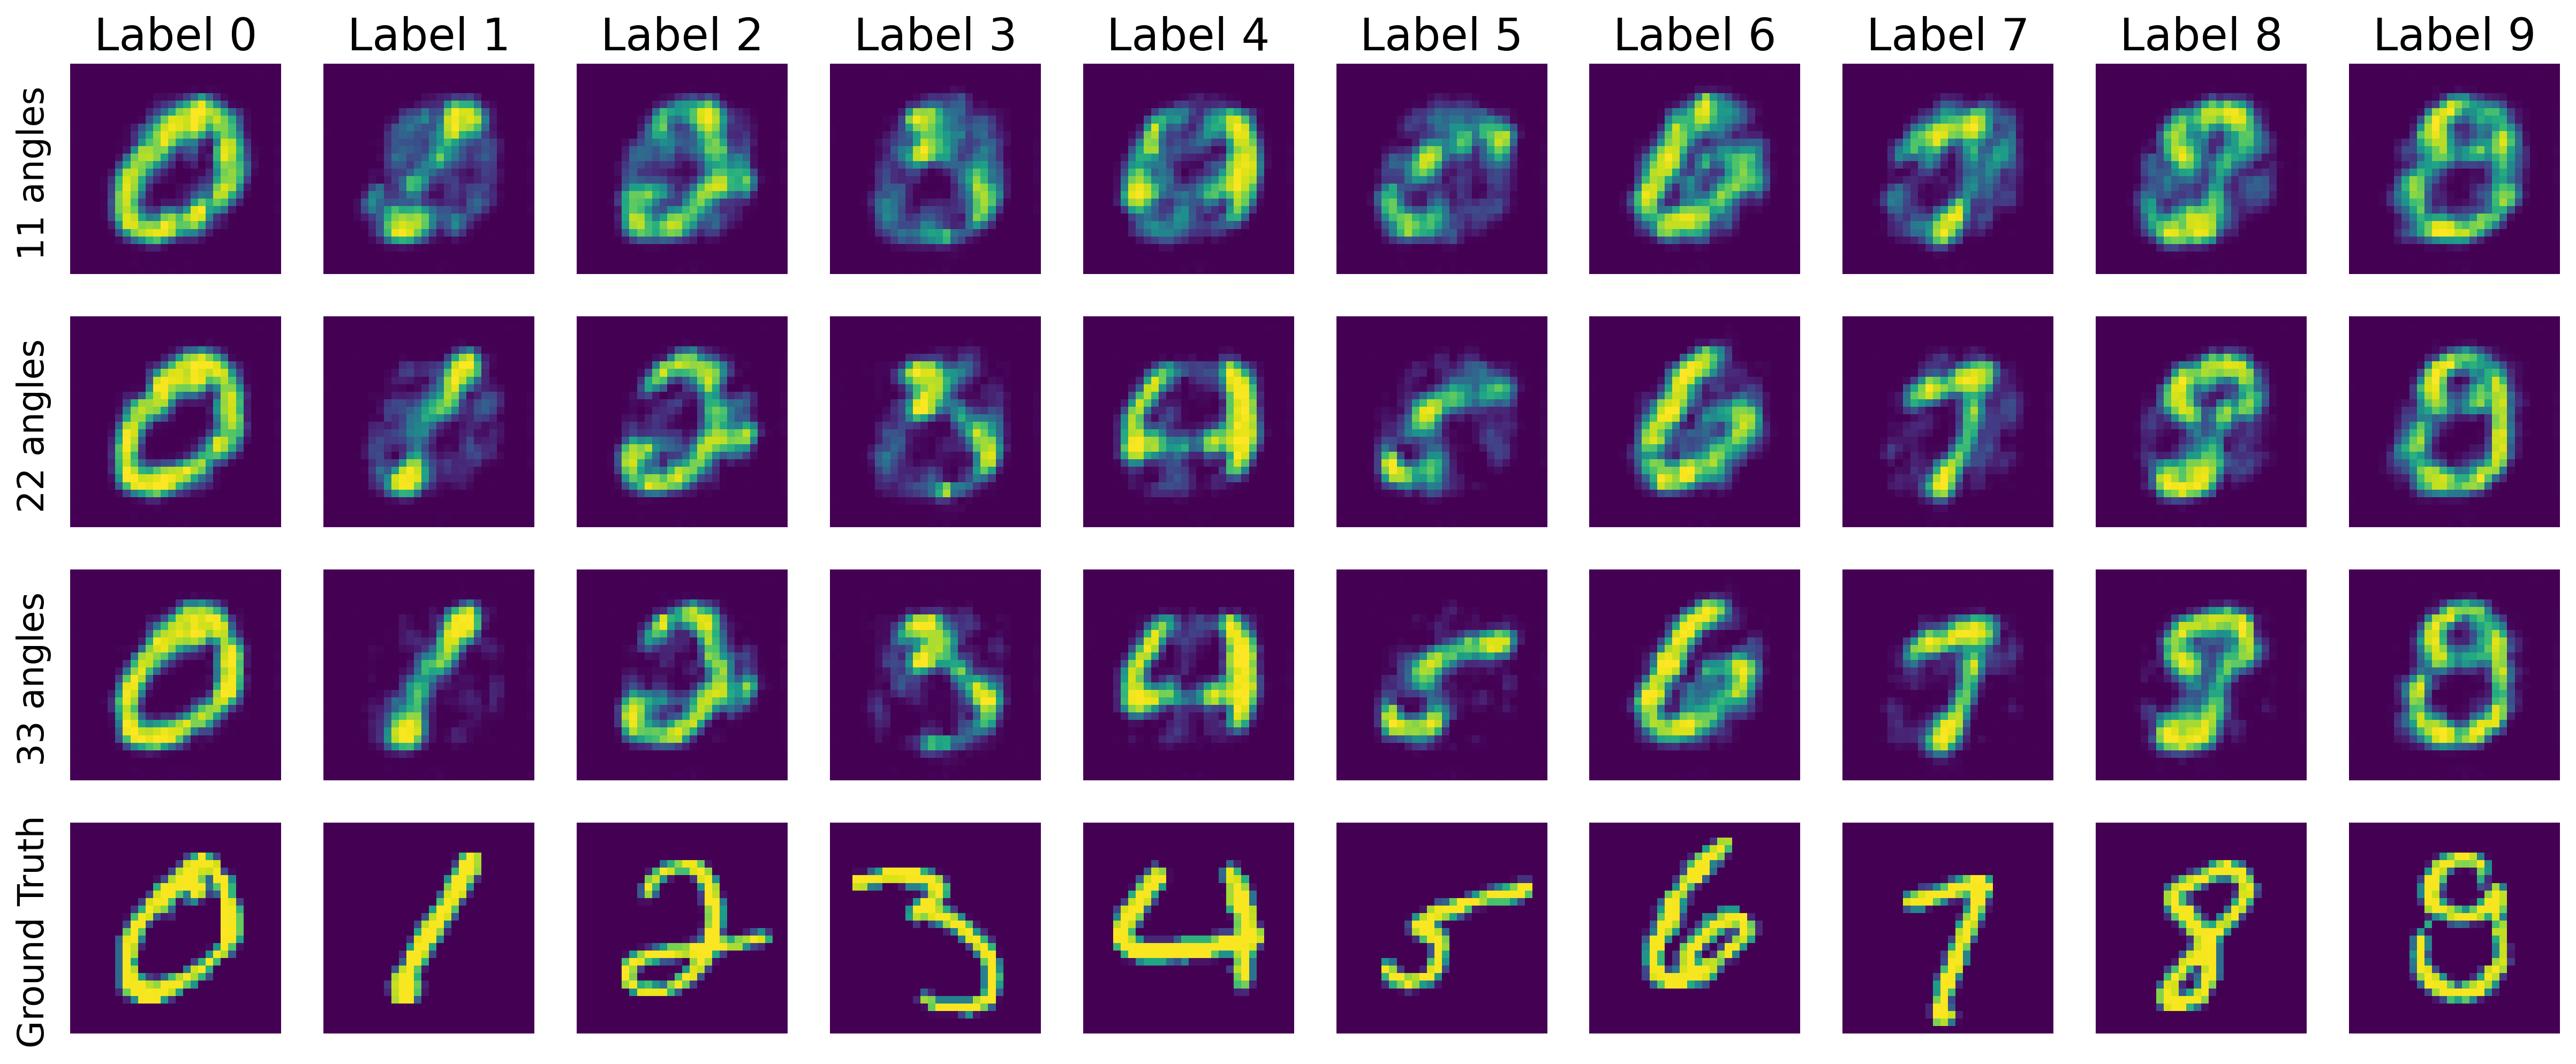

In [6]:
plt.figure(figsize = (20,8), dpi = 300)
for angle in range(len(num_angles)):
    for i in range(10):
        plt.subplot(4,10,angle*10 + i + 1)
        plt.imshow(stack_interest[angle][i,0])
        if i == 0:
            plt.text(-3, 14, f'{num_angles[angle]} angles', rotation=90, va='center', ha='right', color='black', fontsize = 16)

        # plt.title(f'{stack_psnr_mean[angle][i,0]:.2f}')
        if angle == 0:
            plt.title(f'Label {i}', fontsize = 20)
        plt.axis('off')
        plt.clim([0,1])
for i in range(10):
    plt.subplot(4,10,31+i)
    plt.imshow(gt_temp[i,0].squeeze())
    if i == 0:
            plt.text(-3, 14, f'Ground Truth', rotation=90, va='center', ha='right', color='black', fontsize = 16)
    plt.axis('off')
    plt.clim([0,1])
plt.show()

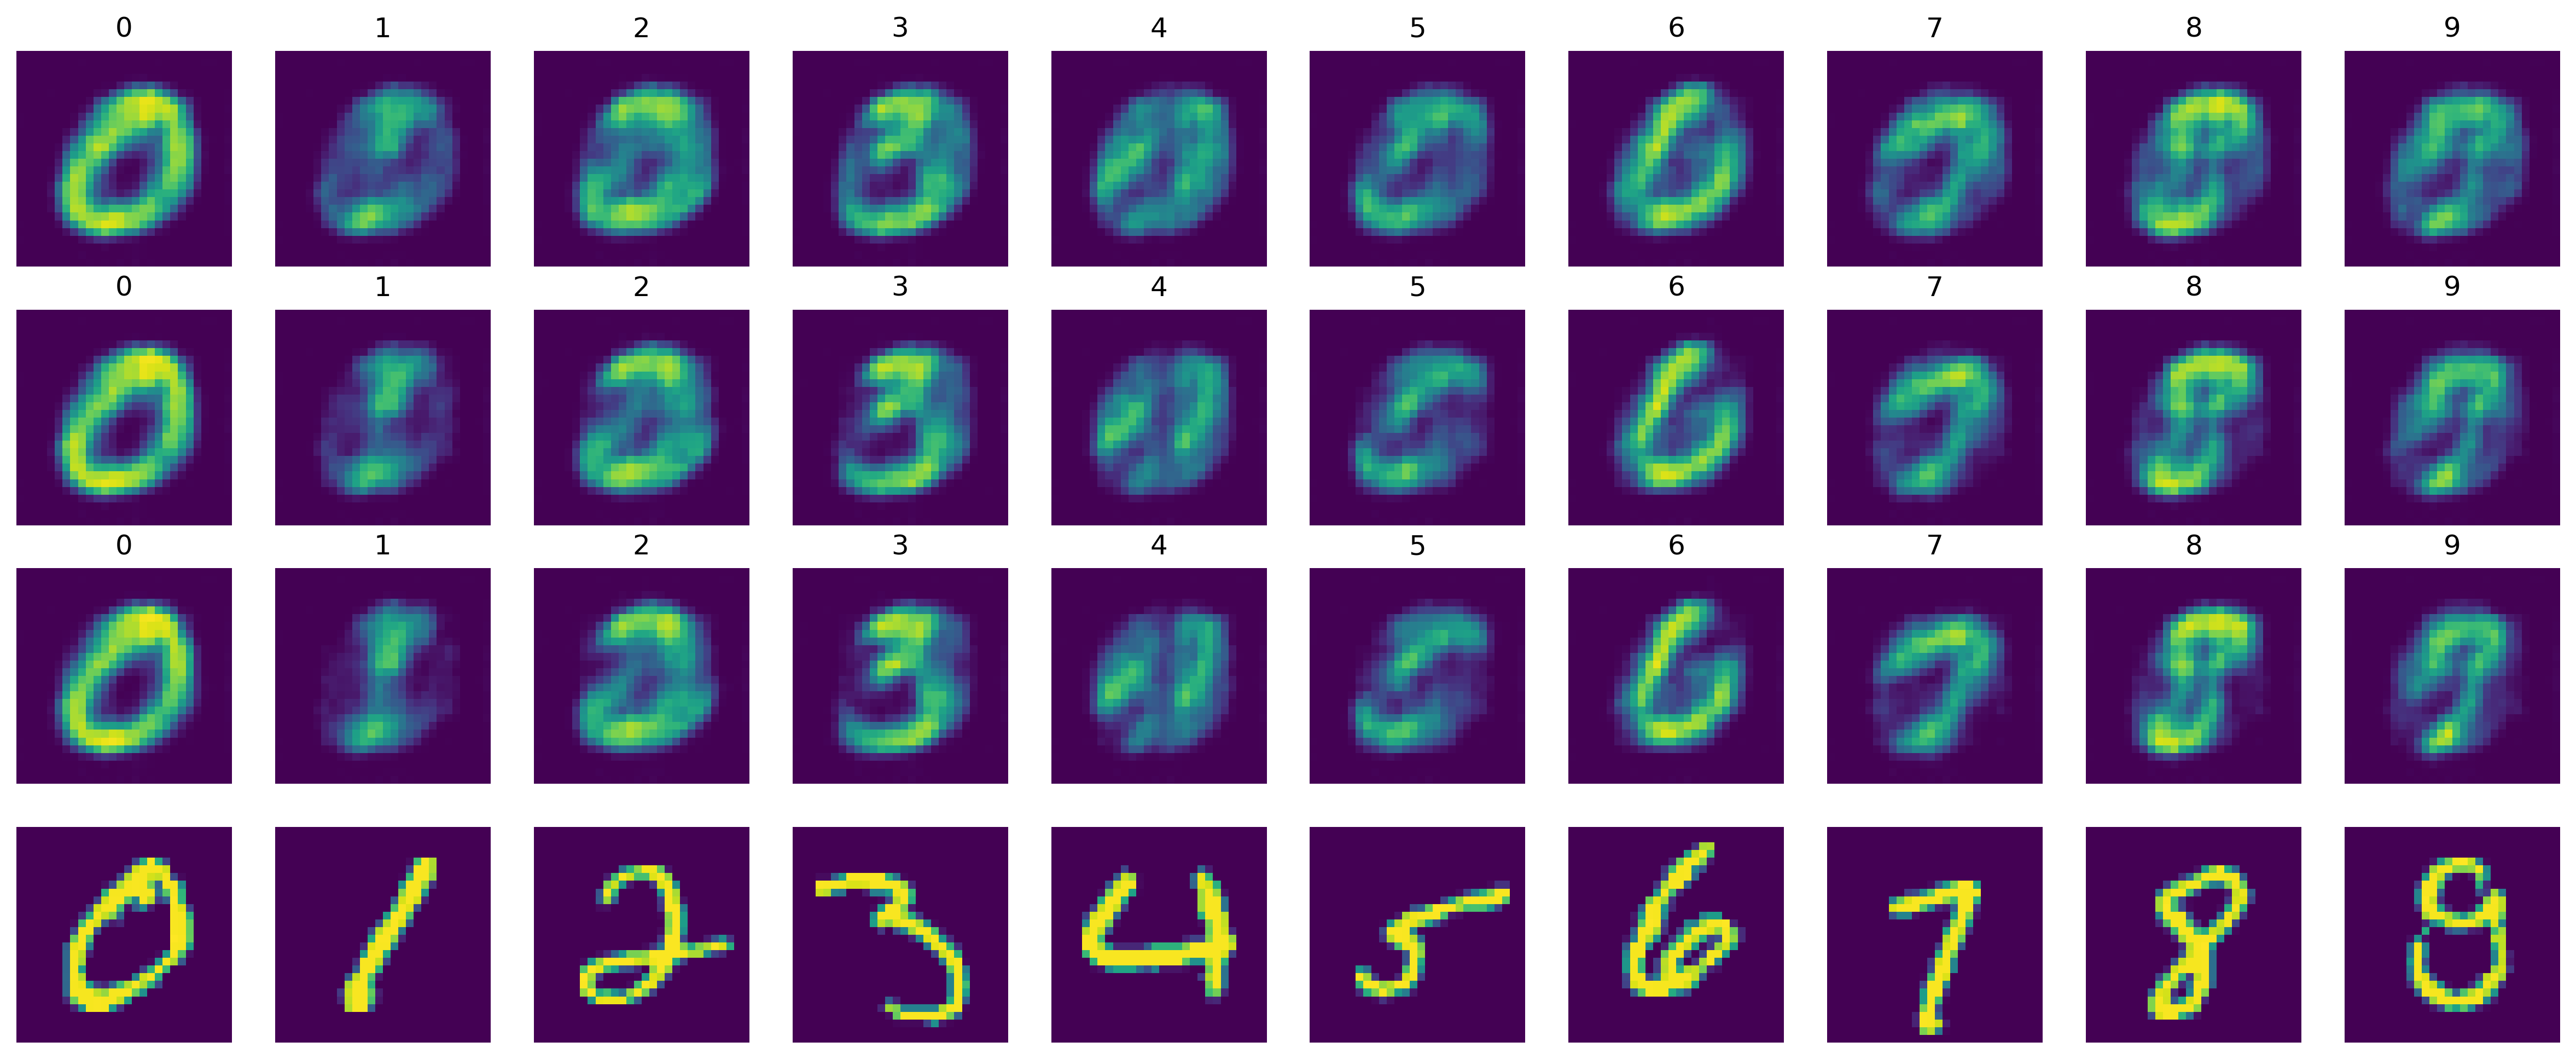

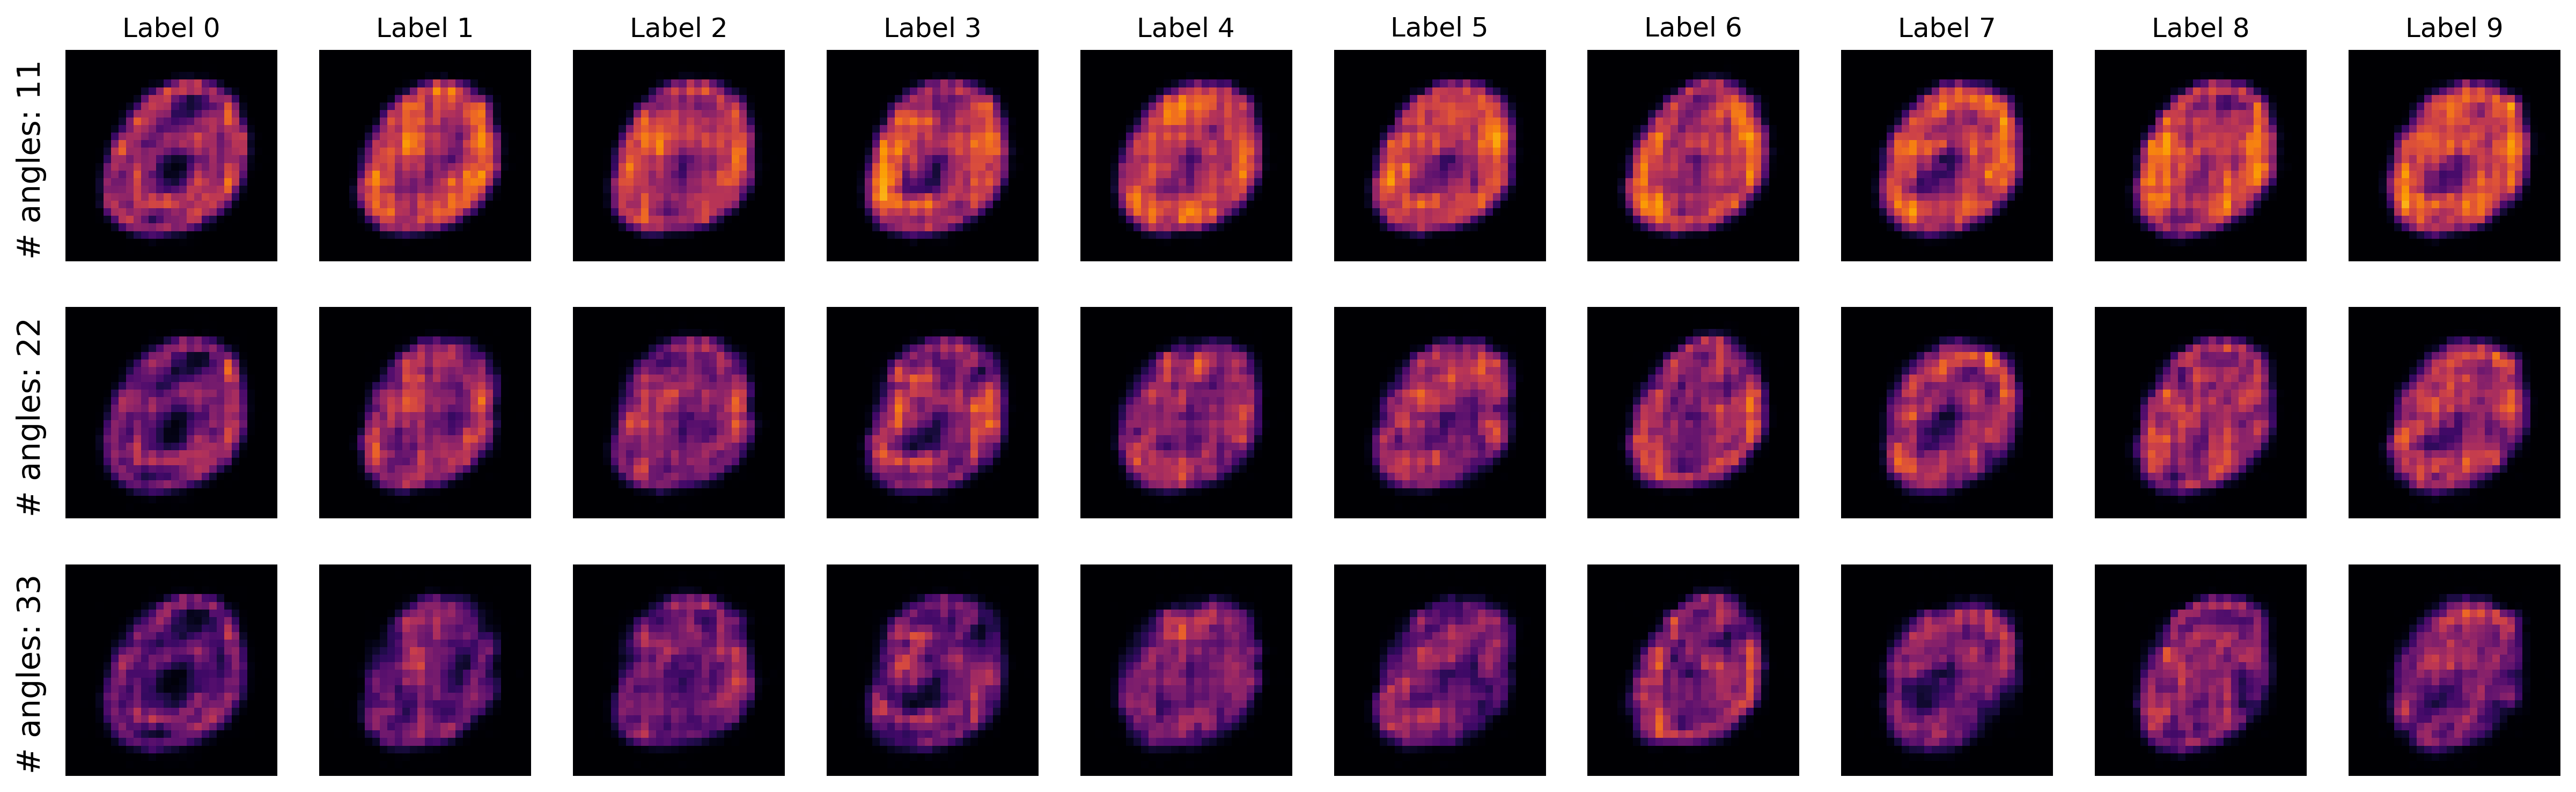

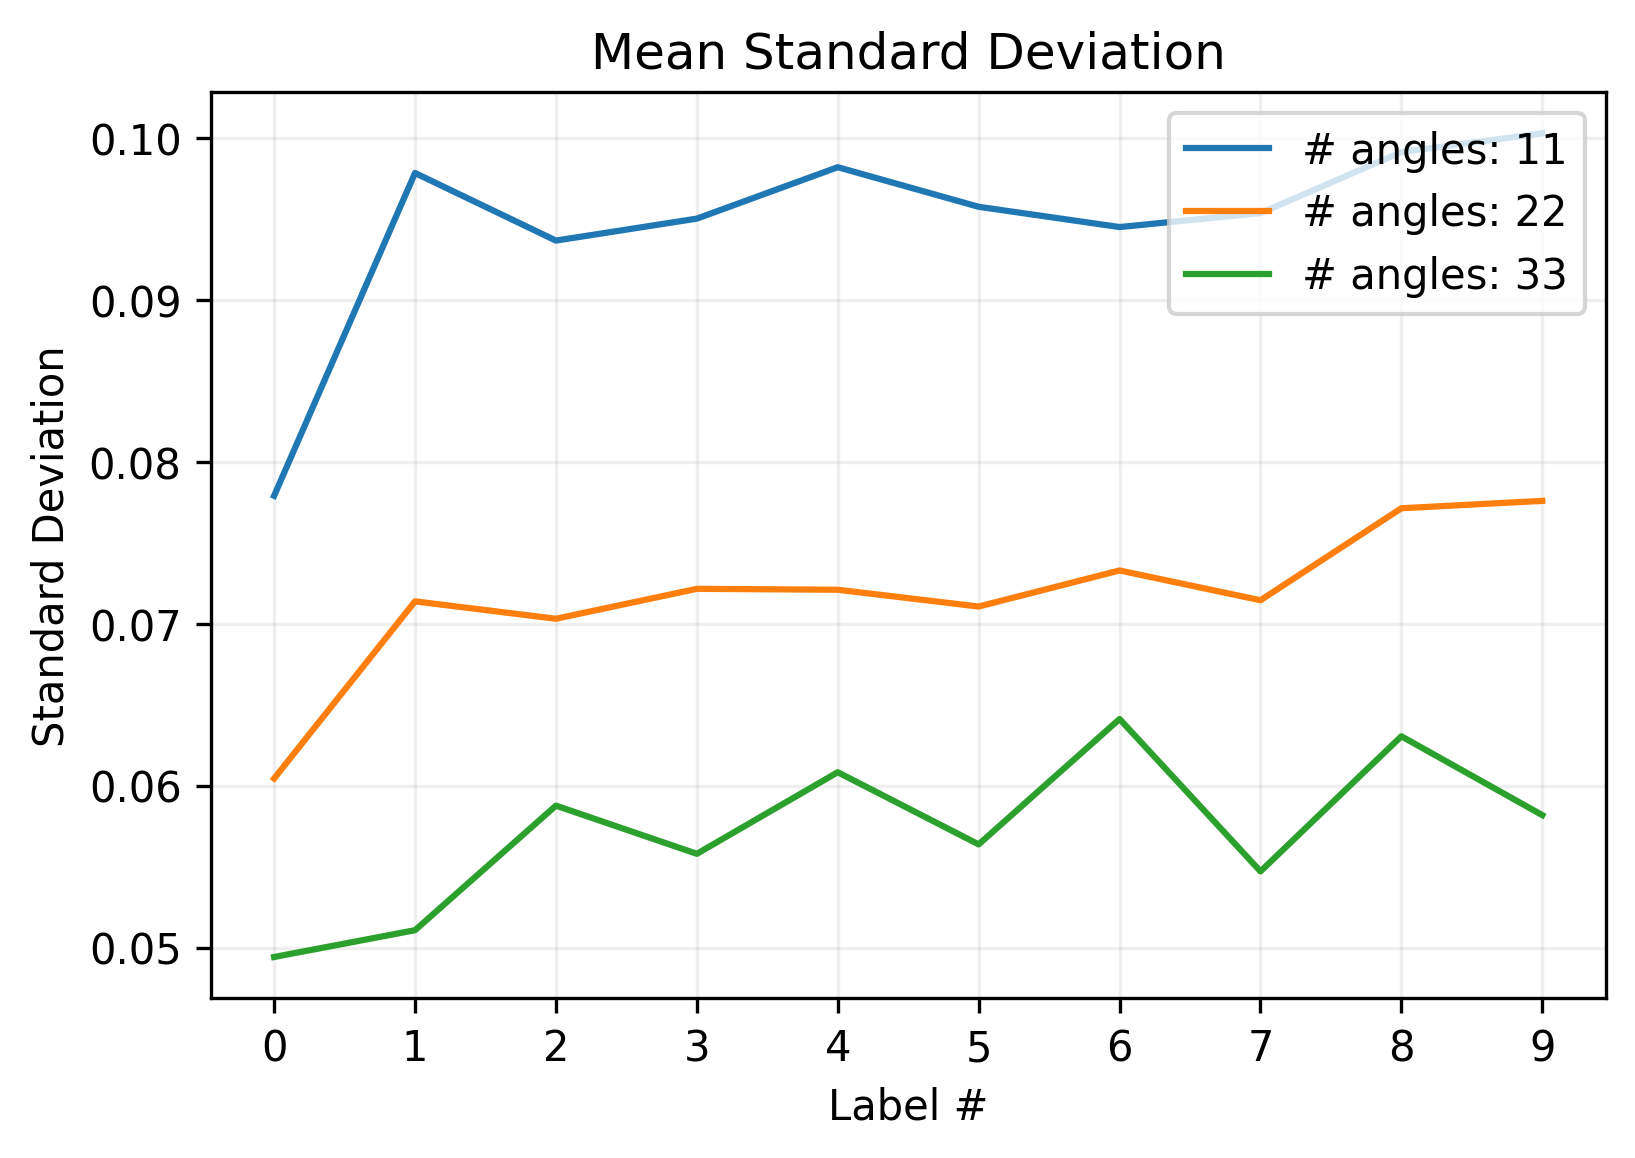

In [7]:
plt.figure(figsize = (20,8), dpi = 300)
for angle in range(len(num_angles)):
    for i in range(10):
        plt.subplot(4,10,angle*10 + i + 1)
        plt.imshow(mean_mean[angle][i])
        plt.title(f'{i}')
        if angle == 0:
            plt.title(f'{i}')
        plt.axis('off')
        plt.clim([0,1])
for i in range(10):
    plt.subplot(4,10,31+i)
    plt.imshow(gt_temp[i,0].squeeze())
    plt.axis('off')
    plt.clim([0,1])

plt.show()

plt.figure(figsize = (20,6), dpi = 300)
for angle in range(len(num_angles)):
    for i in range(10):
        plt.subplot(3,10,angle*10 + i + 1)
        plt.imshow(mean_std[angle][i], cmap='inferno')
        if i == 0:
            plt.text(-3, 14, f'# angles: {num_angles[angle]}', rotation=90, va='center', ha='right', color='black', fontsize = 14)
        if angle == 0:
            plt.title(f'Label {i}')
        plt.axis('off')
        plt.clim([0,std_maxes[angle]])
plt.show()


plt.figure(dpi = 300)
for angle in range(len(num_angles)):
    plt.plot(x, np.mean(mean_std[angle], axis = (1,2)), label = f'# angles: {num_angles[angle]}')
plt.legend(loc = 'upper right')
plt.title('Mean Standard Deviation')
plt.ylabel('Standard Deviation')
plt.xlabel('Label #')
if model_name == 'mnist':
    plt.xticks(range(0, 10, 1))
elif model_name == 'cifar':
    plt.xticks(range(0, 10, 1), rotation = 40)
plt.grid('on', alpha = 0.2)
plt.show()